In [1]:
import pandas as pd
import numpy as np
import copepodTCR as cpp

import seaborn as sn
from matplotlib import pyplot as plt

# Figure 5. Identification of target epitopes with combinatorial minigene pools.

Experimental and model results
of a CCP assay with copepodTCR for the T cell reporter cell lines expressing HLA-A02+ restricted YLQ-TCR1
with its known cognate peptide, shown in blue letters, encoded by a minigene.

In [2]:
## Flow cytometry
table = pd.read_csv('./data/FC_YLQ_activation-minigenes.tsv', sep = "\t")
cpp_scheme = pd.read_csv('./data/peptide-addresses_table_minigenes.tsv', sep = "\t")

## pooling parameters
ep_length = 15
n_pools = 8
iters = 4

### C
Bayesian mixture model of observed pool activation signal (orange) for the read out obtained by flow cytometry. Blue lines show posterior draws from the fitted Bayesian mixture model, representing uncertainty in the inferred activation-signal distribution. The black line shows the mean of the posterior distribution.

Sequential sampling (2 chains in 1 job)
CompoundStep
>NUTS: [negative, offset_proportion, p, sigma_neg, sigm_pos, pool_dist, sigma_data]
>BinaryGibbsMetropolis: [assign]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 6 seconds.
There were 247 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [lik, negative_obs]


Output()

Posterior mean of p: 0.505
No drop-outs were detected
Cognate peptides: ['LLALHRSYLTPGDSSSGWTAGAAAYYVGYLQPRTFLLKYNENGTITDAVDCALDPLSETK']
Peptide candidates: ['LLALHRSYLTPGDSSSGWTAGAAAYYVGYLQPRTFLLKYNENGTITDAVDCALDPLSETK']


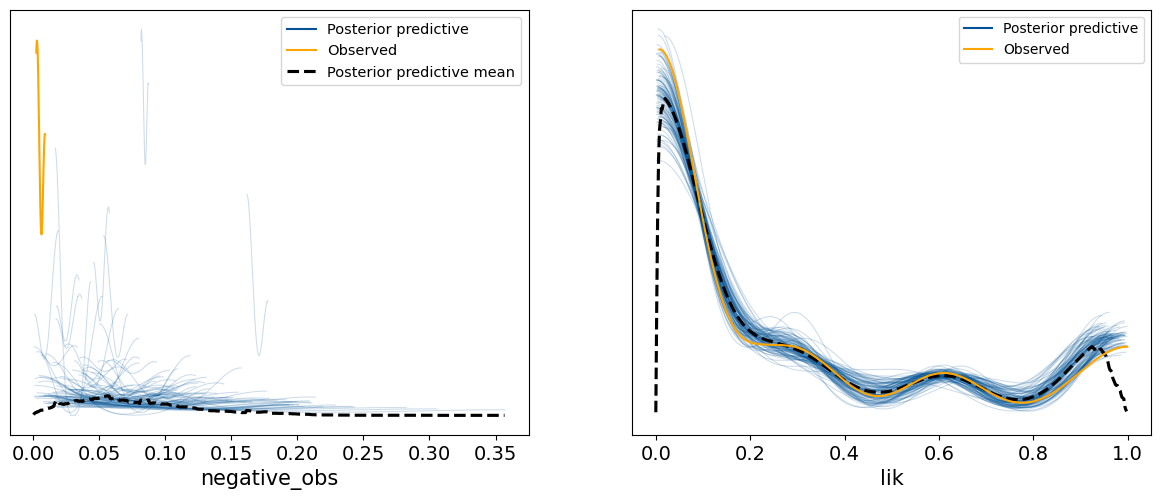

In [3]:
## preparing data for the model /100 because there are percentages
obs = np.array(table['YLQ_fc(%)'][(table['Pool'] != 'mock') & (table['Pool'] != 'pept')])/100
## pool indices
inds = np.array(table['Pool'][(table['Pool'] != 'mock') & (table['Pool'] != 'pept')]).astype(int)
inds = list(np.array(inds).astype(int)-1)
## negative control
neg_f1 = np.array(table['YLQ_fc(%)'][table['Pool'] == 'mock'])/100

## fitting the model
model, fig, probs, n_c, pp, parameters = cpp.activation_model(obs, n_pools, inds, neg_f1)
## calculating peptide probabilities
peptide_probs = cpp.peptide_probabilities(cpp_scheme, probs)
## decision-tree algorithm
n_act_pools, message, most, possible = cpp.results_analysis(peptide_probs, probs, cpp_scheme)
print(message)
print(f'Cognate peptides: {most}')
print(f'Peptide candidates: {possible}')

### B
 Inferred
probability (from C) of each measurement coming from the distribution of activated pools (green) and from
a distribution of non-activated pools (gray).

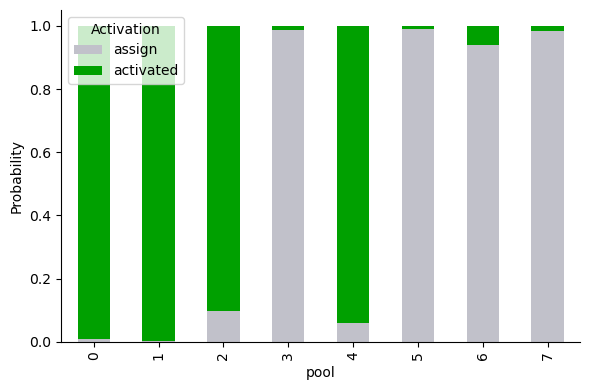

In [4]:
probs['activated'] = 1-probs['assign']
ax = probs.plot(kind="bar", stacked=True, figsize=(6, 4), color=["#C1C1CA", "#00A000"])
plt.legend(title="Activation")
plt.ylabel('Probability')
plt.tight_layout()
sn.despine()

### A
Flow cytometry read out as percentage of GFP-producing
(activated) cells in the T cell activation assay (y-axis) for each pool in the design (x-axis), with pools detected
as activated/non-activated in green and gray, respectively (determined from model fit in B.).

<Axes: title={'center': 'LLALHRSYLTPGDSSSGWTAGAAAYYVGYLQPRTFLLKYNENGTITDAVDCALDPLSETK'}, xlabel='Pools', ylabel='Log10 of activated T cell percentage'>

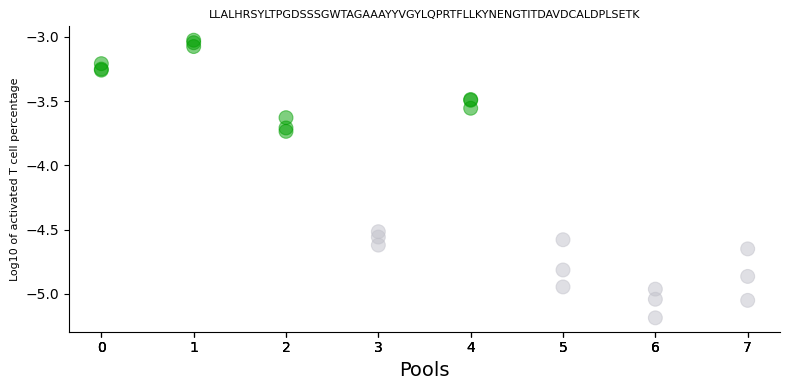

In [5]:
cpp.poolplot(probs, obs, inds, most)

### D
Per-peptide probabilities calculated from B. The size of the circle
shows the difference between the number of activated and non-activated pools to which a peptide was added.

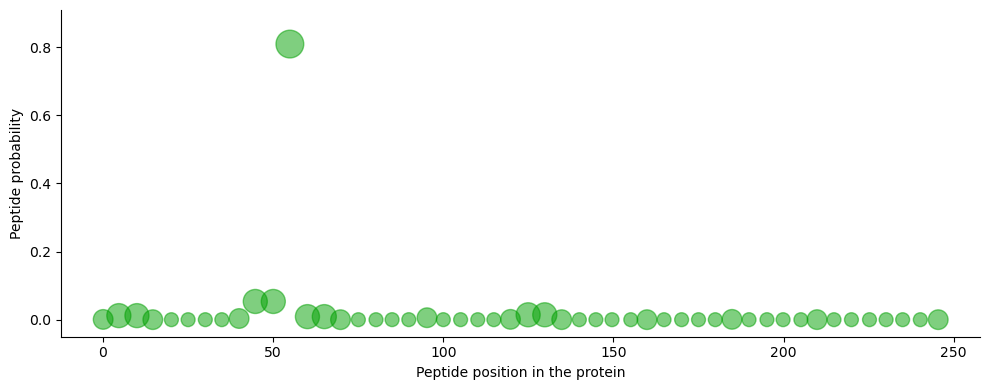

In [6]:
fig, axes = plt.subplots(1, 1, figsize=(10, 4))
cpp.bubbleplot(peptide_probs, ax = axes)
sn.despine()